# Roblox in the Middle East: is it going viral?

**Question:** is Roblox engagement in the Middle East accelerating, and how much are Middle Eastern players behind hits such as **Sarab**?

**Caveat:** no source we hold splits Roblox CCU by country or region (SRS scan, Rolimons and Rotrends are all global). The Middle East read therefore comes from three proxies:
1. **Sensor Tower mobile app data** (DAU and minutes by country). Mobile only, no PC or console.
2. **New 1k+ hits among Arabic-named games** (global CCU, Consistent panel).
3. **Sarab's hour-of-day CCU profile** against the platform's. A peak in Gulf afternoon rather than US afternoon points to a Middle Eastern audience. This is inferred, not measured.

### Takeaways (latest 7 days of data; Sensor Tower to 3-6 Oct, CCU to 8 Oct)
- **Roblox mobile engagement in the Middle East is growing far faster than worldwide, once Egypt is excluded.** For Saudi Arabia, UAE, Kuwait, Oman and Lebanon combined, DAU is **+39% y/y** and minutes **+86%**, against +5% and +7% worldwide. 90 days ago the same group's DAU was only +8%.
  - **Saudi Arabia leads:** 2.9M DAU, +48% y/y, with minutes +90%.
  - **Egypt is down about 64% y/y** and has been all quarter. Including Egypt, the six-country total is +7% DAU and +40% minutes.
- **The upswing started in late August, before Sarab existed** (created 24 Sep). Sarab may have added to the late-September leg. The app data doesn't yet cover Sarab's 8 Oct jump.
- **Sarab reached 78.6k peak CCU on 8 Oct, #15 on Roblox**, up from about 50k and #42 on 3 Oct.
  - It is the biggest of the 50 Arabic-named games to reach 1k+ CCU since 2024. The next is Arabian Keyboard at 54k.
  - It peaks at **15:00 Riyadh**, compared with 19:00 for Roblox overall, and falls to 5% of its peak overnight (the platform only falls to 61%).
  - That pattern fits a concentrated Middle Eastern audience. This is inferred from timing, not measured.
- **Arabic-named breakouts are not a wave.** Each month they are about 0.5-1% of games reaching 1k+ CCU, flat since 2024. Sarab is an outlier.

**Added 12 Oct 2026:** sections 4-6 cover صيد الضبّان, a second Saudi-timed hit, plus Roblox and TikTok mobile usage split into Saudi Arabia, the wider Middle East and the rest of the world.

In [1]:
import os
import re
import warnings
from decimal import Decimal
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import snowflake.connector

warnings.filterwarnings("ignore", category=DeprecationWarning)  # numpy generic-timedelta noise from pandas

ME_COUNTRIES = ["SA", "AE", "KW", "OM", "EG", "LB"]  # Arab Middle East with unbroken Sensor Tower DAU and minutes
COUNTRY_NAMES = {"SA": "Saudi Arabia", "AE": "UAE", "KW": "Kuwait", "OM": "Oman", "EG": "Egypt", "LB": "Lebanon",
                 "ME": "Middle East (6)", "ME_ex_EG": "Middle East excl. Egypt", "WW": "Worldwide"}
ROBLOX_KEYS = ("431946152", "com.roblox.client")  # main iOS and Android apps; excludes Roblox VN
SARAB = 10767825538
HIT_THRESHOLD = 1000
SEEN_WITHIN_DAYS = 30
START = "2024-01-01"
TODAY = pd.Timestamp.today().normalize()
# Latest complete Monday-to-Sunday week.
WEEK_END = TODAY - pd.Timedelta(days=TODAY.weekday() + 1)  # last Sunday before today
WEEK_START = WEEK_END - pd.Timedelta(days=6)

CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)

# Validated reference palette (dataviz skill): categorical slots 1-2, muted ink for context.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID, SHADE = "#0b0b0b", "#52514e", "#898781", "#e6e5e1", "#f0efec"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.titlecolor": INK, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.axisbelow": True, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})

conn = snowflake.connector.connect(
    connection_name=os.getenv("SNOWFLAKE_CONNECTION", "default"),
)


def q(sql: str) -> pd.DataFrame:
    df = conn.cursor().execute(sql).fetch_pandas_all()
    df.columns = [c.lower() for c in df.columns]
    for c in df:
        if c == "date":
            df[c] = pd.to_datetime(df[c])
        elif df[c].dtype == object and isinstance(df[c].dropna().iloc[0] if df[c].notna().any() else None, Decimal):
            df[c] = df[c].astype(float)  # Snowflake NUMBER arrives as Decimal
    return df


def source_note(fig, text):
    fig.text(0.01, 0.005, text, fontsize=8, color=MUTED, ha="left", va="bottom")


def save(fig, name):
    fig.savefig(CHARTS / f"{name}.png", dpi=200, bbox_inches="tight")


print(f"Latest complete week: {WEEK_START:%d %b} - {WEEK_END:%d %b %Y}")

Initiating login request with your identity provider. A browser window should have opened for you to complete the login. If you can't see it, check existing browser windows, or your OS settings. Press CTRL+C to abort and try again...


Latest complete week: 05 Oct - 11 Oct 2026


## 1. Middle East mobile engagement: DAU and minutes, y/y

Sensor Tower `sensortower.common.core`, Roblox iOS + Android, summed across Saudi Arabia, UAE, Kuwait, Oman, Egypt and Lebanon (the Arab Middle East countries with DAU and minutes throughout; Qatar stops in late 2025, and Bahrain, Iraq and Jordan have downloads only).

- **y/y** is the trailing 7-day total against the same 7 days 364 days earlier, so weekdays line up.
- Minutes are delivered a few days behind DAU, so the minutes line ends earlier.

In [2]:
countries_sql = ", ".join(f"'{c}'" for c in ME_COUNTRIES + ["WW"])
st = q(f'''
    SELECT date, country_code, SUM(dau) AS dau, SUM(minutes) AS minutes
    FROM sensortower.common.core
    WHERE product_key IN {ROBLOX_KEYS}
        AND country_code IN ({countries_sql})
        AND date >= DATEADD(day, -364 - 130, CURRENT_DATE)
    GROUP BY 1, 2
''')
# One column per country; a day only counts if every device row reported the metric.
wide = {m: st.pivot(index="date", columns="country_code", values=m).sort_index().asfreq("D") for m in ("dau", "minutes")}
for m, df in wide.items():
    df["ME"] = df[ME_COUNTRIES].sum(axis=1, min_count=len(ME_COUNTRIES))
    ex_eg = [c for c in ME_COUNTRIES if c != "EG"]
    df["ME_ex_EG"] = df[ex_eg].sum(axis=1, min_count=len(ex_eg))


def yoy_7d(s: pd.Series) -> pd.Series:
    r = s.rolling(7, min_periods=7).sum()
    return r / r.shift(364) - 1


yoy = {m: df.apply(yoy_7d) for m, df in wide.items()}
last = {m: pd.Timestamp(df["ME"].last_valid_index()) for m, df in wide.items()}
print({m: f"{d:%Y-%m-%d}" for m, d in last.items()})

{'dau': '2026-10-09', 'minutes': '2026-10-03'}


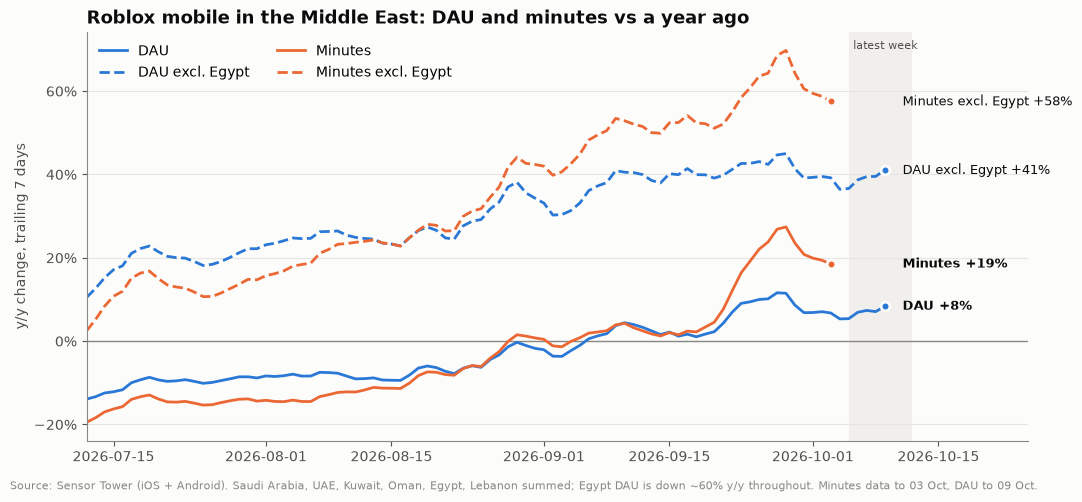

In [3]:
WINDOW_START = last["dau"] - pd.Timedelta(days=89)
fig, ax = plt.subplots(figsize=(11, 5))
ax.axvspan(WEEK_START, WEEK_END + pd.Timedelta(days=1), color=SHADE, lw=0, zorder=0)
ax.text(WEEK_START + pd.Timedelta(hours=12), 0.98, "latest week", transform=ax.get_xaxis_transform(),
        fontsize=8, color=INK2, va="top")
ax.axhline(0, color=MUTED, lw=1)
end_labels = []
for m, label, color in [("dau", "DAU", BLUE), ("minutes", "Minutes", ORANGE)]:
    for col, ls, suffix in [("ME", "-", ""), ("ME_ex_EG", "--", " excl. Egypt")]:
        s = yoy[m][col].loc[WINDOW_START:last[m]]
        ax.plot(s.index, s, color=color, ls=ls, label=label + suffix)
        ax.scatter([s.index[-1]], [s.iloc[-1]], color=color, s=40, zorder=3, edgecolor="#fcfcfb", linewidth=2)
        end_labels.append([s.iloc[-1], f"{label}{suffix} {s.iloc[-1]:+.0%}", col == "ME"])
# Direct labels at the right edge, nudged apart so they don't overlap.
end_labels.sort()
for i in range(1, len(end_labels)):
    end_labels[i][0] = max(end_labels[i][0], end_labels[i - 1][0] + 0.06)
for y, text, bold in end_labels:
    ax.text(last["dau"] + pd.Timedelta(days=2), y, text, color=INK, fontsize=9, va="center",
            fontweight="bold" if bold else "normal")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
ax.set_xlim(WINDOW_START, last["dau"] + pd.Timedelta(days=16))
ax.set_title("Roblox mobile in the Middle East: DAU and minutes vs a year ago")
ax.set_ylabel("y/y change, trailing 7 days")
ax.legend(loc="upper left", ncols=2)
source_note(fig, "Source: Sensor Tower (iOS + Android). Saudi Arabia, UAE, Kuwait, Oman, Egypt, Lebanon summed; Egypt DAU is down ~60% y/y throughout. "
                 f"Minutes data to {last['minutes']:%d %b}, DAU to {last['dau']:%d %b}.")
fig.tight_layout(rect=(0, 0.03, 1, 1))
save(fig, "1_me_dau_minutes_yoy")

In [4]:
# Per-country read for the most recent 7 days of each metric.
rows = []
for c in ME_COUNTRIES + ["ME", "ME_ex_EG", "WW"]:
    rows.append({
        "market": COUNTRY_NAMES[c],
        f"avg DAU (7d to {last['dau']:%d %b})": wide["dau"][c].loc[:last["dau"]].tail(7).mean(),
        "DAU y/y": yoy["dau"][c].loc[last["dau"]],
        f"min/DAU/day (7d to {last['minutes']:%d %b})": (wide["minutes"][c].loc[:last["minutes"]].tail(7).sum()
                                                      / wide["dau"][c].loc[:last["minutes"]].tail(7).sum()),
        "Minutes y/y": yoy["minutes"][c].loc[last["minutes"]],
        "DAU y/y, 90d ago": yoy["dau"][c].loc[WINDOW_START],
    })
country_table = pd.DataFrame(rows).set_index("market")
country_table.style.format({
    country_table.columns[0]: "{:,.0f}", "DAU y/y": "{:+.0%}", country_table.columns[2]: "{:.0f}",
    "Minutes y/y": "{:+.0%}", "DAU y/y, 90d ago": "{:+.0%}",
}, na_rep="-")

,avg DAU (7d to 09 Oct),DAU y/y,min/DAU/day (7d to 03 Oct),Minutes y/y,"DAU y/y, 90d ago"
market,,,,,
Saudi Arabia,"2,920,074",+51%,62,+54%,+9%
UAE,"668,397",+11%,64,+47%,+12%
Kuwait,"203,565",+71%,71,+375%,+52%
Oman,"48,419",+28%,42,+7%,-1%
Egypt,"480,367",-64%,56,-68%,-64%
Lebanon,"269,211",+25%,83,+51%,+3%
Middle East (6),"4,590,035",+8%,63,+19%,-14%
Middle East excl. Egypt,"4,109,667",+41%,64,+58%,+10%
Worldwide,"162,492,255",+6%,57,-0%,-1%


## 2. New 1k+ hits among Arabic-named games

The **new hits** logic matches the Tableau NewHitsDashboard (rebuilt in `roblox/investigations/panel_games_5k_ccu.ipynb`, section 6):
- A game's **hit date** is the first date its daily average CCU in `game_trend` (`datasource = 'Consistent'`) reaches 1,000.
- Hits first seen in the panel **under 30 days after the game's creation** are genuinely new games (blue). Only 9 Arabic-named games since 2024 qualify, so older Arabic-named games reaching 1k for the first time are stacked on top (grey). Some of those are coverage expansions rather than real breakouts.

**Arabic-named:** any name the game has ever had (2-hourly scan names, Rotrends and game metadata) contains at least two Arabic letters and no Persian-only letters (پ چ ژ ک گ ی). Names change often, so a current-name filter would miss renamed games.
- **Sarab** is listed under its English name; its Arabic title (سراب) appeared in one scan snapshot only, so it is added by hand.

In [5]:
ARABIC_SCRIPT = "[؀-ۿ]"
names = q(f'''
    SELECT DISTINCT universe_id, game_name FROM bots.rblx.game_rank WHERE REGEXP_LIKE(game_name, '.*{ARABIC_SCRIPT}.*', 's')
    UNION
    SELECT DISTINCT game_id, game_name FROM bots.rblx.rotrend_games_adj WHERE REGEXP_LIKE(game_name, '.*{ARABIC_SCRIPT}.*', 's')
    UNION
    SELECT DISTINCT universe_id, game_name FROM bots.rblx.game_meta_v3 WHERE REGEXP_LIKE(game_name, '.*{ARABIC_SCRIPT}.*', 's')
''')
ARABIC_LETTER = re.compile("[ء-ي]")
PERSIAN_ONLY = re.compile("[پچژکگی]")


def is_arabic(name: str) -> bool:
    return len(ARABIC_LETTER.findall(name)) >= 2 and not PERSIAN_ONLY.search(name)


names["arabic"] = names["game_name"].map(is_arabic)
arabic_name = names[names["arabic"]].groupby("universe_id")["game_name"].first()
arabic_ids = set(arabic_name.index) | {SARAB}
print(f"{names['universe_id'].nunique():,} games with any Arabic-script name; {len(arabic_ids):,} pass the Arabic rule (incl. Sarab)")

9,821 games with any Arabic-script name; 9,743 pass the Arabic rule (incl. Sarab)


In [6]:
new_hits = q(f'''
    WITH created_feeds AS (
        SELECT universe_id, MIN(created) :: DATE AS created
        FROM (
            SELECT universe_id, created_at AS created FROM bots.rblx.game_meta_v3 WHERE universe_id > 0
            UNION ALL
            SELECT universe_id, create_date FROM bots.rblx.game_meta_v2 WHERE universe_id > 0
            UNION ALL
            SELECT game_id, created FROM bots.rblx.rotrend_list
            UNION ALL
            SELECT game_id, created FROM bots.rblx.rotrend_topgames
        )
        WHERE created >= '2006-01-01'
        GROUP BY 1
    ),
    games AS (
        -- As the Tableau NewHitsDashboard: first date TRUNC(mean_players) >= threshold.
        SELECT
            universe_id,
            MIN(IFF(TRUNC(mean_players) >= {HIT_THRESHOLD}, date, NULL)) AS hit_date,
            MIN(date) AS first_seen,
            MIN(IFF(create_date >= '2006-01-01', create_date, NULL)) :: DATE AS create_date,
            MAX(mean_players) AS peak_daily_mean,
            MAX(max_players) AS peak_ccu,
            MAX_BY(game_name, date) AS latest_name
        FROM bots.rblx.game_trend
        WHERE datasource = 'Consistent'
            AND universe_id IS NOT NULL
        GROUP BY 1
        HAVING hit_date IS NOT NULL
    )
    SELECT
        g.universe_id,
        g.hit_date AS date,
        COALESCE(g.create_date, c.created) AS created,
        DATEDIFF(day, COALESCE(g.create_date, c.created), g.first_seen) AS seen_lag_days,
        g.peak_daily_mean,
        g.peak_ccu,
        g.latest_name
    FROM games g
    LEFT JOIN created_feeds c
        ON c.universe_id = g.universe_id
    WHERE g.hit_date >= '{START}'
''')
new_hits["created"] = pd.to_datetime(new_hits["created"])
new_hits["seen_within_30d"] = new_hits["seen_lag_days"] < SEEN_WITHIN_DAYS
new_hits["arabic"] = new_hits["universe_id"].isin(arabic_ids)
new_hits["month"] = new_hits["date"].dt.to_period("M").dt.to_timestamp()

arabic_hits = new_hits[new_hits["arabic"]]
monthly = pd.DataFrame({
    "arabic_new_games": arabic_hits[arabic_hits["seen_within_30d"]].groupby("month").size(),
    "arabic_established": arabic_hits[~arabic_hits["seen_within_30d"]].groupby("month").size(),
    "all_hits_new_games": new_hits[new_hits["seen_within_30d"]].groupby("month").size(),
    "all_hits": new_hits.groupby("month").size(),
}).reindex(pd.date_range(START, TODAY, freq="MS")).fillna(0).astype(int)
monthly["arabic_share_new_games"] = monthly["arabic_new_games"] / monthly["all_hits_new_games"]
monthly["arabic_share_all"] = (monthly["arabic_new_games"] + monthly["arabic_established"]) / monthly["all_hits"]
latest_week = new_hits[new_hits["date"].between(WEEK_START, WEEK_END)]
print(f"Arabic-named hits since {START}: {len(arabic_hits)} of {len(new_hits):,} "
      f"({int(arabic_hits['seen_within_30d'].sum())} new games, first seen < {SEEN_WITHIN_DAYS} days after creation)")
print(f"Latest week {WEEK_START:%d %b}-{WEEK_END:%d %b}: {len(latest_week)} hits, {int(latest_week['arabic'].sum())} Arabic-named")
monthly.tail(12)

Arabic-named hits since 2024-01-01: 51 of 9,500 (9 new games, first seen < 30 days after creation)
Latest week 05 Oct-11 Oct: 137 hits, 1 Arabic-named


,arabic_new_games,arabic_established,all_hits_new_games,all_hits,arabic_share_new_games,arabic_share_all
2025-11-01,0,0,70,308,0.000000,0.000000
2025-12-01,0,3,94,306,0.000000,0.009804
2026-01-01,0,1,132,330,0.000000,0.003030
2026-02-01,0,0,133,311,0.000000,0.000000
2026-03-01,1,1,160,350,0.006250,0.005714
2026-04-01,0,2,130,335,0.000000,0.005970
2026-05-01,0,0,153,346,0.000000,0.000000
2026-06-01,2,1,124,335,0.016129,0.008955
2026-07-01,1,1,142,440,0.007042,0.004545
2026-08-01,0,2,156,395,0.000000,0.005063


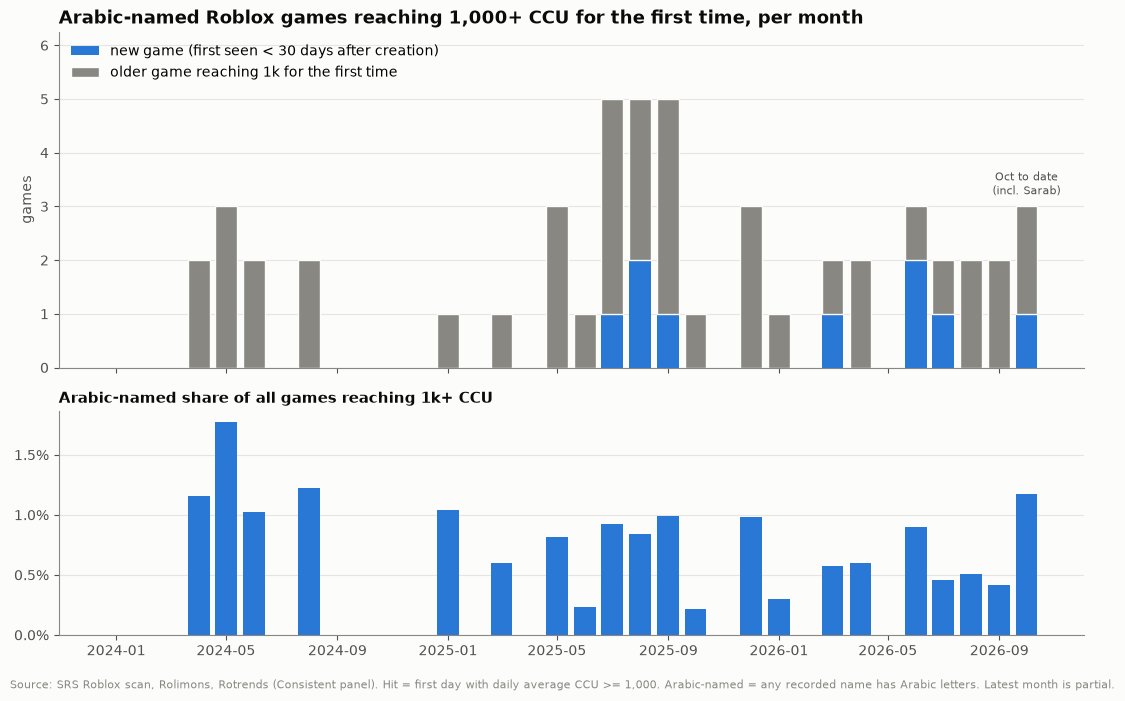

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
x = monthly.index
ax1.bar(x, monthly["arabic_new_games"], width=24, color=BLUE, label=f"new game (first seen < {SEEN_WITHIN_DAYS} days after creation)")
ax1.bar(x, monthly["arabic_established"], width=24, bottom=monthly["arabic_new_games"], color=MUTED,
        edgecolor="#fcfcfb", linewidth=1, label="older game reaching 1k for the first time")
ax1.set_title(f"Arabic-named Roblox games reaching {HIT_THRESHOLD:,}+ CCU for the first time, per month")
ax1.set_ylabel("games")
ax1.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax1.legend(loc="upper left")
ax2.bar(x, monthly["arabic_share_all"], width=24, color=BLUE)
ax2.set_title("Arabic-named share of all games reaching 1k+ CCU", fontsize=11)
ax2.yaxis.set_major_locator(mticker.MultipleLocator(0.005))
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=1))
cur = monthly.index[-1]
cur_ids = set(new_hits.loc[new_hits["arabic"] & (new_hits["month"] == cur), "universe_id"])
ax1.annotate(f"{cur:%b} to date" + ("\n(incl. Sarab)" if SARAB in cur_ids else ""),
             (cur, monthly[["arabic_new_games", "arabic_established"]].iloc[-1].sum()), xytext=(0, 6),
             textcoords="offset points", ha="center", va="bottom", fontsize=8, color=INK2)
ax1.margins(y=0.25)
source_note(fig, f"Source: SRS Roblox scan, Rolimons, Rotrends (Consistent panel). Hit = first day with daily average CCU >= {HIT_THRESHOLD:,}. "
                 "Arabic-named = any recorded name has Arabic letters. Latest month is partial.")
fig.tight_layout(rect=(0, 0.03, 1, 1))
save(fig, "2_arabic_new_hits")

In [8]:
# Arabic-named hits over the last 12 months (all hits, flagged where first seen soon after creation).
recent = new_hits[new_hits["arabic"] & (new_hits["date"] >= TODAY - pd.DateOffset(months=12))].copy()
recent["arabic_name"] = recent["universe_id"].map(arabic_name).fillna("سراب (manual)")
(recent.sort_values("date", ascending=False)
 [["universe_id", "latest_name", "arabic_name", "created", "date", "seen_within_30d", "peak_daily_mean", "peak_ccu"]]
 .rename(columns={"date": "hit_date"})
 .style.format({"peak_daily_mean": "{:,.0f}", "peak_ccu": "{:,.0f}", "created": "{:%Y-%m-%d}", "hit_date": "{:%Y-%m-%d}"}, na_rep="-")
 .hide(axis="index"))

universe_id,latest_name,arabic_name,created,hit_date,seen_within_30d,peak_daily_mean,peak_ccu
10769149947,صيد الضبّان,صيد الضبّان,-,2026-10-11,False,"14,138","18,908"
10301442866,عرب تايم (arab time),عرب تايم (arab time),2026-06-10,2026-10-04,False,"2,026","3,846"
10767825538,Sarab,سراب,2026-09-24,2026-10-03,True,"50,836","98,260"
8982950355,العسكرية بلانتوم | تحديث✨,العسكرية بلانتوم | الرتب,2025-10-19,2026-09-10,False,"1,264","3,509"
9215289961,East Riyadh[Update],شرق الرياض | East Riyadh,2025-11-21,2026-09-03,False,"1,261","2,456"
5125369493,Driving Simulator,محاكي القيادة,2023-09-24,2026-08-28,False,"4,253","8,813"
9811924734,كيبورد العرب | Arabian Keyboard +1,[مراحل جديده] كيبورد العرب | Arabian Keyboard,2026-02-28,2026-08-02,False,"11,649","54,203"
10403345264,شااالية رعد | الاصلي,شااالية رعد | الاصلي,2026-06-27,2026-07-16,True,"3,658","4,047"
10227167939,شااليهه الريل,شااليهه الريل,2026-05-26,2026-07-01,False,"6,057","6,057"
4240706197,الربيع كشته (رول بلاي) Saudi-Kashtah,الربيع كشته (رول بلاي) Saudi-Kashtah,2022-12-31,2026-06-17,False,"5,419","5,419"


## 3. Sarab

Universe 10767825538 (creator group "Patience Zone", survival genre, created 24 Sep 2026). In our panel from 3 Oct.

**Daily CCU:** `game_trend`, Consistent. Today's partial day is dropped.

**Hour-of-day profile:** the 2-hourly SRS scan (`game_rank`, timestamps in UTC), averaged over the last 7 days of scans. Each line is indexed to its own peak, so the chart compares the *shape* of the day, not size. The platform line is the total across all scanned games.

In [9]:
sarab = q(f'''
    SELECT date, mean_players, max_players, rank_player
    FROM bots.rblx.game_trend
    WHERE datasource = 'Consistent' AND universe_id = {SARAB} AND date < CURRENT_DATE
    ORDER BY date
''').set_index("date")
sarab

,mean_players,max_players,rank_player
date,,,
2026-10-03,30170.625000,50311.0,42
2026-10-04,18157.583333,50455.0,38
2026-10-05,18017.916667,49990.0,31
2026-10-06,18333.583333,51190.0,27
2026-10-07,20413.500000,51926.0,26
2026-10-08,39720.500000,78590.0,15
2026-10-09,50835.750000,98260.0,14
2026-10-10,39084.750000,78508.0,25
2026-10-11,31970.583333,66198.0,30


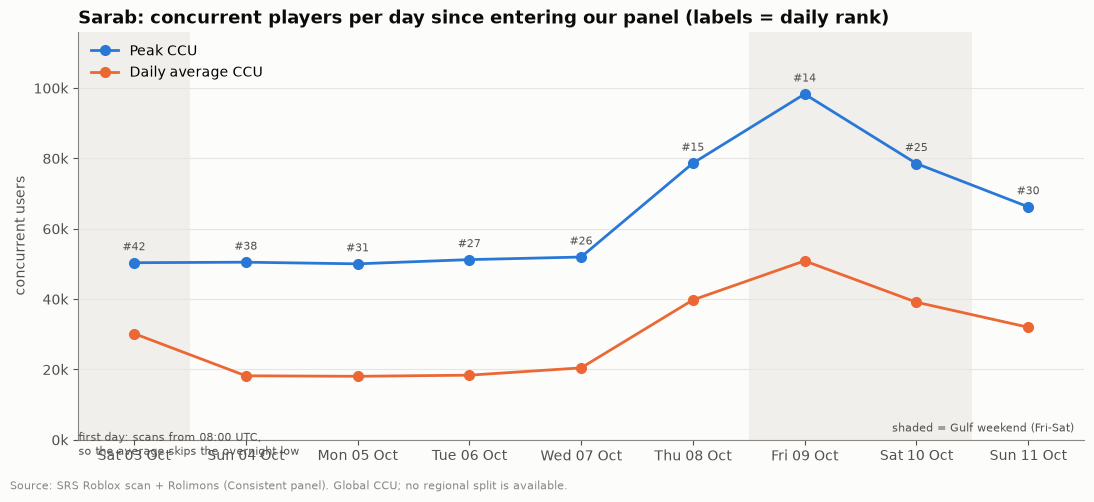

In [10]:
fig, ax = plt.subplots(figsize=(11, 5))
# Gulf weekend is Friday-Saturday.
for d in sarab.index[sarab.index.dayofweek.isin([4, 5])]:
    ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color=SHADE, lw=0, zorder=0)
ax.plot(sarab.index, sarab["max_players"], color=BLUE, marker="o", markersize=7, label="Peak CCU")
ax.plot(sarab.index, sarab["mean_players"], color=ORANGE, marker="o", markersize=7, label="Daily average CCU")
for d, r in sarab.iterrows():
    ax.annotate(f"#{int(r['rank_player'])}", (d, r["max_players"]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=8, color=INK2)
first = sarab.index[0]
if first == pd.Timestamp("2026-10-03"):
    ax.annotate("first day: scans from 08:00 UTC,\nso the average skips the overnight low", (first, sarab["mean_players"].iloc[0]),
                xytext=(-40, -70), textcoords="offset points", fontsize=8, color=INK2, ha="left", va="top")
ax.text(0.99, 0.02, "shaded = Gulf weekend (Fri-Sat)", transform=ax.transAxes, ha="right", fontsize=8, color=INK2)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
ax.set_ylim(0, sarab["max_players"].max() * 1.18)
ax.set_xlim(sarab.index[0] - pd.Timedelta(hours=12), sarab.index[-1] + pd.Timedelta(hours=12))
ax.set_xticks(sarab.index)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a %d %b"))
ax.set_title("Sarab: concurrent players per day since entering our panel (labels = daily rank)")
ax.set_ylabel("concurrent users")
ax.legend(loc="upper left")
source_note(fig, "Source: SRS Roblox scan + Rolimons (Consistent panel). Global CCU; no regional split is available.")
fig.tight_layout(rect=(0, 0.03, 1, 1))
save(fig, "3_sarab_daily_ccu")

In [11]:
hourly = q(f'''
    SELECT rundate,
        SUM(IFF(universe_id = {SARAB}, players, 0)) AS sarab,
        SUM(players) AS platform
    FROM bots.rblx.game_rank
    WHERE rundate >= DATEADD(day, -7, (SELECT MAX(rundate) FROM bots.rblx.game_rank))
    GROUP BY 1
''')
hourly = hourly[hourly["sarab"] > 0]
profile = hourly.groupby(hourly["rundate"].dt.hour)[["sarab", "platform"]].mean()
profile_idx = profile / profile.max() * 100
print(f"Scans used: {hourly['rundate'].min():%d %b %H:%M} to {hourly['rundate'].max():%d %b %H:%M} UTC ({len(hourly)} scans)")
print(f"Sarab peak hour {profile['sarab'].idxmax():02d}:00 UTC; platform peak hour {profile['platform'].idxmax():02d}:00 UTC")
print(f"Sarab trough/peak: {profile['sarab'].min() / profile['sarab'].max():.0%}; platform: {profile['platform'].min() / profile['platform'].max():.0%}")
profile.round(0)

Scans used: 04 Oct 22:01 to 11 Oct 22:01 UTC (85 scans)
Sarab peak hour 12:00 UTC; platform peak hour 16:00 UTC
Sarab trough/peak: 8%; platform: 65%


,sarab,platform
rundate,,
0,9263.0,9906575.0
2,5755.0,9896212.0
4,5463.0,8929809.0
6,12349.0,8635484.0
8,24795.0,8774970.0
10,50104.0,9611112.0
12,67809.0,11423289.0
14,51002.0,12665192.0
16,50514.0,13320834.0


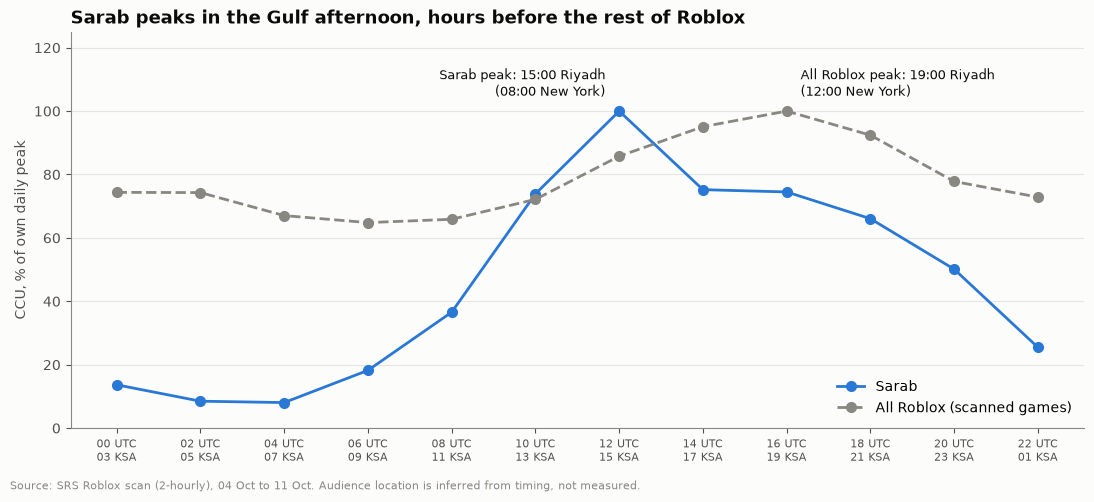

In [12]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(profile_idx.index, profile_idx["sarab"], color=BLUE, marker="o", markersize=7, label="Sarab")
ax.plot(profile_idx.index, profile_idx["platform"], color=MUTED, marker="o", markersize=7, ls="--", label="All Roblox (scanned games)")
for col, who, ha, dx in [("sarab", "Sarab", "right", -10), ("platform", "All Roblox", "left", 10)]:
    h = profile_idx[col].idxmax()
    ax.annotate(f"{who} peak: {(h + 3) % 24:02d}:00 Riyadh\n({(h - 4) % 24:02d}:00 New York)",
                (h, 100), xytext=(dx, 8), textcoords="offset points", ha=ha, va="bottom", fontsize=9, color=INK)
ticks = list(range(0, 24, 2))
ax.set_xticks(ticks)
ax.set_xticklabels([f"{h:02d} UTC\n{(h + 3) % 24:02d} KSA" for h in ticks], fontsize=8)
ax.set_ylim(0, 125)
ax.set_ylabel("CCU, % of own daily peak")
ax.set_title("Sarab peaks in the Gulf afternoon, hours before the rest of Roblox")
ax.legend(loc="lower right")
source_note(fig, f"Source: SRS Roblox scan (2-hourly), {hourly['rundate'].min():%d %b} to {hourly['rundate'].max():%d %b}. "
                 "Audience location is inferred from timing, not measured.")
fig.tight_layout(rect=(0, 0.03, 1, 1))
save(fig, "4_sarab_hourly_profile")

## 4. صيد الضبّان ("Dhab hunting"): a second Saudi-timed hit (added 12 Oct 2026)

Universe 10769149947 ([roblox.com/games/82347957379349](https://www.roblox.com/games/82347957379349/unnamed)). The SRS scan picked it up on 11 Oct; it is not yet in the Rotrends list or Rolimons.

### Takeaways (scan to 11 Oct 22:00 UTC; Sensor Tower DAU to 9 Oct, minutes to 3 Oct)
- **صيد الضبّان entered the SRS scan on 11 Oct at 18.9k CCU** (14.1k daily average, #125 that day).
  - From 15:00 to 01:00 Riyadh it fell 66%, in line with Sarab (-74%) and unlike Roblox overall (-27%).
  - That is the pattern of a concentrated Gulf audience, as with Sarab. It is inferred from timing, not measured.
- **Its effect is not in the app data yet,** because Sensor Tower DAU runs to 9 Oct.
- **Roblox mobile DAU was +6.3% y/y worldwide** over the 7 days to 9 Oct.
  - **Saudi Arabia** is 1.8% of DAU but adds +0.64pp at +51% y/y, about a tenth of worldwide growth.
  - **The wider Middle East** subtracts 0.41pp (-27% y/y). That is Egypt (-64%, -0.55pp); the Gulf and Lebanon are up.
  - **The rest of the world** adds +6.08pp (+6.3%).
- **The Middle East's net y/y contribution has turned positive.** Over the last 12 weeks, Saudi Arabia's contribution rose from about +0.4pp in July to +0.6-0.7pp since September. The wider Middle East drag shrank from -0.7pp to -0.4pp. Combined, the region went from about -0.3pp to +0.2pp of worldwide y/y growth.
- **Week to week, the Middle East barely moves the worldwide trend.**
  - **Latest week (7 days to 9 Oct):** worldwide DAU was +1.1% w/w. Saudi Arabia contributed -0.01pp (-0.3% w/w), the wider Middle East +0.00pp, and the rest of the world all of it (+1.10pp).
  - **Saudi Arabia's biggest w/w swings** over the 12 weeks were +0.14pp (week to 25 Sep, Saudi DAU about +10% w/w) and -0.18pp (week to 2 Oct). The rest of the world swings by up to ±3pp.
  - **The wider Middle East's largest move** was -0.12pp (week to 18 Sep).
  - **Saudi daily DAU** ran +2% to +6.5% w/w on 6-9 Oct, around Sarab's jump on 8 Oct.
- **Minutes tell a slightly different story for the week to 3 Oct.** Saudi Roblox minutes fell 9.6% w/w, taking 0.21pp off worldwide minutes growth (+0.1%) and outweighing the wider Middle East (-0.04pp).
- **TikTok usage in Saudi Arabia is growing slowly:** DAU +4.6% and minutes +13% y/y, against +13% and +17% worldwide.
  - Saudi Arabia's and the wider Middle East's w/w contributions to TikTok are within ±0.06pp every week.
  - None of our TikTok data measures engagement with this game or with Roblox content (see section 6).


**Scan readings:** `game_rank`, 2-hourly, UTC. Charts label the game "Dhab Hunting". As with Sarab, no source we hold splits a game's players by country, so audience location is inferred from the time of day it is played.

In [13]:
NEW_GAME = 10769149947
NEW_LABEL = "Dhab Hunting"  # chart label; matplotlib cannot lay out Arabic beside Latin text
AQUA = "#1baf7a"  # categorical slot 3

new_game = q(f'''
    SELECT rundate, MAX(players) AS players, MAX_BY(game_name, insert_update_time) AS game_name
    FROM bots.rblx.game_rank
    WHERE universe_id = {NEW_GAME} AND file_name ILIKE '%scan%'
    GROUP BY 1
    ORDER BY 1
''')
first_seen = new_game["rundate"].min()
scans = q(f'''
    SELECT rundate,
        SUM(IFF(universe_id = {NEW_GAME}, players, 0)) AS new_game,
        SUM(IFF(universe_id = {SARAB}, players, 0)) AS sarab,
        SUM(players) AS platform
    FROM bots.rblx.game_rank
    WHERE file_name ILIKE '%scan%' AND rundate >= '{first_seen:%Y-%m-%d %H:%M}'
    GROUP BY 1
    ORDER BY 1
''')
new_daily = q(f'''
    SELECT date, mean_players, max_players, rank_player
    FROM bots.rblx.game_trend
    WHERE datasource = 'Consistent' AND universe_id = {NEW_GAME}
    ORDER BY date
''').set_index("date")
print(f"{NEW_LABEL} ({new_game['game_name'].iloc[-1]}): first scanned {first_seen:%d %b %H:%M} UTC, {len(new_game)} scans to "
      f"{new_game['rundate'].max():%d %b %H:%M} UTC, highest scan so far {new_game['players'].max():,.0f} CCU "
      f"at {new_game.loc[new_game['players'].idxmax(), 'rundate']:%d %b %H:%M} UTC")
new_daily

Dhab Hunting (صيد الضبّان): first scanned 11 Oct 12:01 UTC, 6 scans to 11 Oct 22:01 UTC, highest scan so far 18,908 CCU at 11 Oct 12:01 UTC


,mean_players,max_players,rank_player
date,,,
2026-10-11,14137.5,18908.0,125


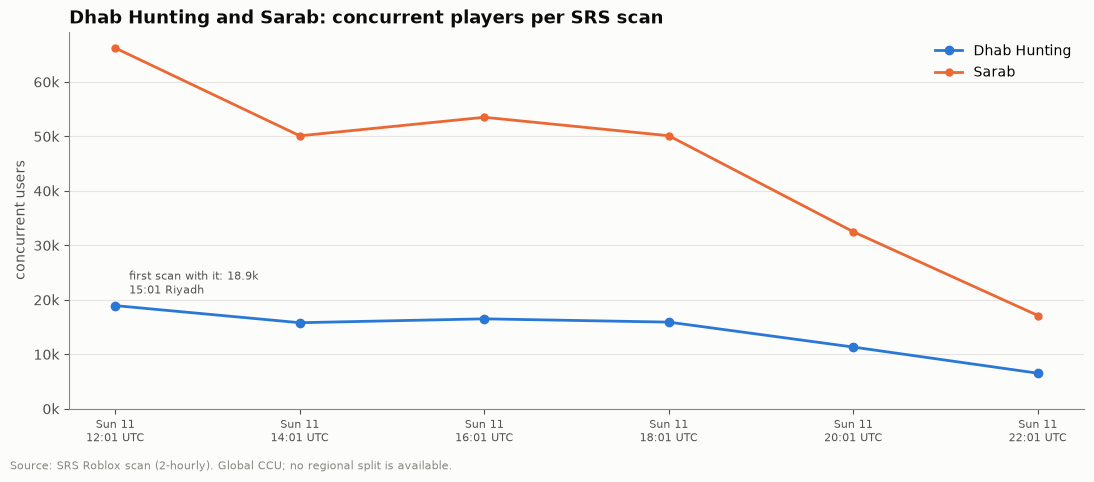

In [14]:
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(scans["rundate"], scans["new_game"] / 1e3, color=BLUE, marker="o", markersize=6, label=NEW_LABEL)
ax.plot(scans["rundate"], scans["sarab"] / 1e3, color=ORANGE, marker="o", markersize=5, label="Sarab")
first = new_game.iloc[0]
ax.annotate(f"first scan with it: {first['players'] / 1e3:.1f}k\n{(first['rundate'] + pd.Timedelta(hours=3)):%H:%M} Riyadh",
            (first["rundate"], first["players"] / 1e3), xytext=(10, 6), textcoords="offset points", ha="left",
            va="bottom", fontsize=8, color=INK2)
ax.set_ylim(bottom=0)
ax.margins(y=0.2)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}k"))
ax.set_title(f"{NEW_LABEL} and Sarab: concurrent players per SRS scan")
ax.set_xticks(scans["rundate"])
ax.set_xticklabels([f"{t:%a %d}\n{t:%H:%M} UTC" for t in scans["rundate"]], fontsize=8)
ax.set_ylabel("concurrent users")
ax.legend(loc="upper right")
source_note(fig, "Source: SRS Roblox scan (2-hourly). Global CCU; no regional split is available.")
fig.tight_layout(rect=(0, 0.03, 1, 1))
save(fig, "5_new_game_ccu")

**Time-of-day shape.** The scan only picked the game up at 12:00 UTC (15:00 Riyadh), so its morning and true peak are not visible yet. Over the hours we do have, each line is indexed to its own reading at the game's first scan. The game falls off into the Gulf evening and night about as steeply as Sarab, while Roblox overall, which peaks in the US afternoon, falls far less. Re-run this once more scans are in to see a full day.

,new_game,sarab,platform
rundate,,,
2026-10-11 12:01:00,18908.0,66198.0,14594695.0
2026-10-11 14:01:00,15768.0,50079.0,15564675.0
2026-10-11 16:01:00,16479.0,53481.0,15736839.0
2026-10-11 18:01:00,15876.0,50091.0,15148497.0
2026-10-11 20:01:00,11296.0,32460.0,12600819.0
2026-10-11 22:01:00,6498.0,17090.0,10713107.0


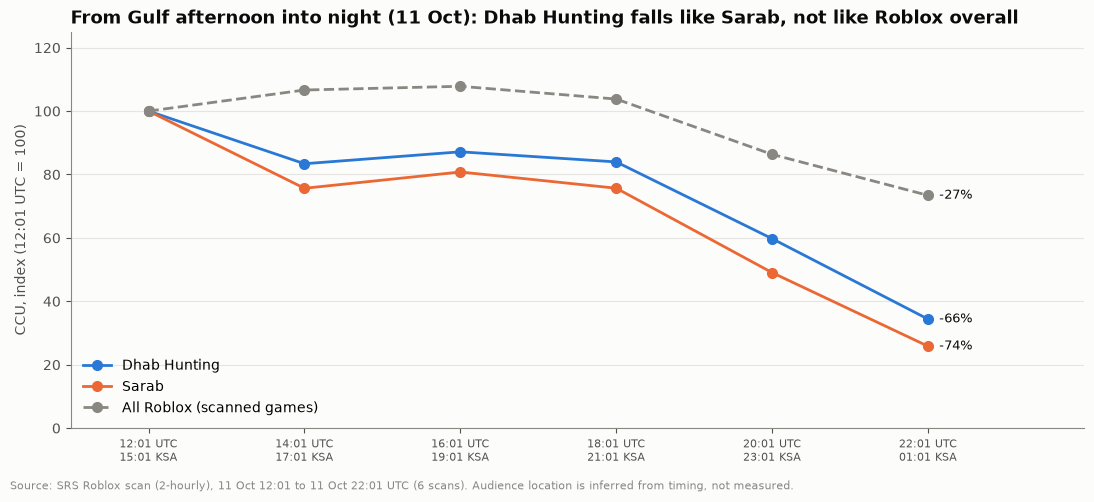

In [15]:
s = scans[scans["new_game"] > 0].set_index("rundate")
idx = s / s.iloc[0] * 100
fig, ax = plt.subplots(figsize=(11, 5))
for col, label, color, ls in [("new_game", NEW_LABEL, BLUE, "-"), ("sarab", "Sarab", ORANGE, "-"),
                              ("platform", "All Roblox (scanned games)", MUTED, "--")]:
    ax.plot(idx.index, idx[col], color=color, ls=ls, marker="o", markersize=7, label=label)
    ax.annotate(f"{idx[col].iloc[-1] - 100:+.0f}%", (idx.index[-1], idx[col].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK)
ax.set_xticks(idx.index)
ax.set_xticklabels([f"{t:%H:%M} UTC\n{t + pd.Timedelta(hours=3):%H:%M} KSA" for t in idx.index], fontsize=8)
ax.set_xlim(idx.index[0] - pd.Timedelta(hours=1), idx.index[-1] + pd.Timedelta(hours=2))
ax.set_ylim(0, 125)
ax.set_ylabel(f"CCU, index ({idx.index[0]:%H:%M} UTC = 100)")
ax.set_title(f"From Gulf afternoon into night ({idx.index[0]:%d %b}): {NEW_LABEL} falls like Sarab, not like Roblox overall")
ax.legend(loc="lower left")
source_note(fig, f"Source: SRS Roblox scan (2-hourly), {s.index.min():%d %b %H:%M} to {s.index.max():%d %b %H:%M} UTC ({len(s)} scans). "
                 "Audience location is inferred from timing, not measured.")
fig.tight_layout(rect=(0, 0.03, 1, 1))
save(fig, "6_new_game_hourly_profile")
s.round(0)

## 5. Roblox mobile DAU growth by region

Sensor Tower `sensortower.common.core`, Roblox iOS + Android, split into:
- **Saudi Arabia.**
- **Wider Middle East:** UAE, Kuwait, Oman, Egypt and Lebanon, the other Arab Middle East markets with unbroken DAU (as in section 1; Qatar's data stops in late 2025).
- **Rest of world:** the worldwide figure less those six.

**Growth** is the trailing 7-day total against the previous 7 days (w/w) and against the same 7 days 364 days earlier (y/y). **Contribution** is each region's change as a share of the worldwide base, in percentage points, so the three regions sum to the worldwide growth.
- Days Sensor Tower has not delivered yet arrive as zeros and are treated as missing.
- The latest DAU day predates 11 Oct, when صيد الضبّان appeared, so the game's effect is not in this data yet. Re-run the section once Sensor Tower catches up.
- **Sensor Tower has revised recent minutes since section 1 was run (9 Oct).** For the same week (to 3 Oct), Saudi Roblox minutes are now **+54% y/y**, not +90%, and about 62 minutes per DAU per day, not 77. DAU barely moved. Sections 1-3 keep their 9 Oct outputs until the notebook is re-run.

In [16]:
ME_WIDER = [c for c in ME_COUNTRIES if c != "SA"]
REGIONS = {"Saudi Arabia": BLUE, "Wider Middle East": ORANGE, "Rest of world": AQUA}
TIKTOK_KEYS = ("835599320", "com.zhiliaoapp.musically", "com.ss.android.ugc.trill")  # iOS, Android (global), Android (Asia)
apps_sql = ", ".join(f"'{k}'" for k in ROBLOX_KEYS + TIKTOK_KEYS)
countries_sql = ", ".join(f"'{c}'" for c in ME_COUNTRIES + ["WW"])
st_apps = q(f'''
    SELECT date, country_code, IFF(product_key IN {ROBLOX_KEYS}, 'Roblox', 'TikTok') AS app,
        SUM(dau) AS dau, SUM(minutes) AS minutes
    FROM sensortower.common.core
    WHERE product_key IN ({apps_sql})
        AND country_code IN ({countries_sql})
        AND date >= DATEADD(day, -364 - 130, CURRENT_DATE)
    GROUP BY 1, 2, 3
''')


def regions(app: str, metric: str) -> pd.DataFrame:
    p = (st_apps[st_apps["app"] == app]
         .pivot_table(index="date", columns="country_code", values=metric, aggfunc="sum")
         .replace(0, float("nan")).asfreq("D"))
    me = p[ME_WIDER].sum(axis=1, min_count=len(ME_WIDER))
    return pd.DataFrame({"Saudi Arabia": p["SA"], "Wider Middle East": me, "Rest of world": p["WW"] - p["SA"] - me,
                         "Worldwide": p["WW"], "Egypt": p["EG"]})


def growth_table(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.Timestamp]:
    last = df[["Saudi Arabia", "Wider Middle East", "Worldwide"]].dropna().index.max()
    r7 = df.rolling(7, min_periods=7).sum()
    cur, wk, yr = r7.loc[last], r7.loc[last - pd.Timedelta(days=7)], r7.loc[last - pd.Timedelta(days=364)]
    t = pd.DataFrame({
        "avg per day, 7d": cur / 7,
        "share": cur / cur["Worldwide"],
        "w/w": cur / wk - 1,
        "w/w contribution (pp)": (cur - wk) / wk["Worldwide"] * 100,
        "y/y": cur / yr - 1,
        "y/y contribution (pp)": (cur - yr) / yr["Worldwide"] * 100,
    })
    t = t.rename(index={"Egypt": "  of which Egypt"}).reindex(
        ["Saudi Arabia", "Wider Middle East", "  of which Egypt", "Rest of world", "Worldwide"])
    return t, last


LAGS = {"w/w": 7, "y/y": 364}  # trailing 7 days against the previous 7, or the same 7 days 364 days earlier


def growth_7d(s: pd.Series, lag: int) -> pd.Series:
    r = s.rolling(7, min_periods=7).sum()
    return r / r.shift(lag) - 1


FMT = {"avg per day, 7d": "{:,.0f}", "share": "{:.1%}", "w/w": "{:+.1%}",
       "w/w contribution (pp)": "{:+.2f}", "y/y": "{:+.1%}", "y/y contribution (pp)": "{:+.2f}"}
region_data = {(app, m): regions(app, m) for app in ("Roblox", "TikTok") for m in ("dau", "minutes")}
roblox_dau, roblox_last = growth_table(region_data[("Roblox", "dau")])
print(f"Roblox DAU, trailing 7 days to {roblox_last:%a %d %b}")
roblox_dau.style.format(FMT)

Roblox DAU, trailing 7 days to Fri 09 Oct


,"avg per day, 7d",share,w/w,w/w contribution (pp),y/y,y/y contribution (pp)
Saudi Arabia,"2,920,074",1.8%,-0.3%,-0.01,+50.6%,+0.64
Wider Middle East,"1,669,960",1.0%,+0.1%,+0.00,-27.3%,-0.41
of which Egypt,"480,367",0.3%,+9.2%,+0.03,-63.7%,-0.55
Rest of world,"157,902,220",97.2%,+1.1%,+1.10,+6.3%,+6.08
Worldwide,"162,492,255",100.0%,+1.1%,+1.10,+6.3%,+6.31


In [17]:
roblox_min, min_last = growth_table(region_data[("Roblox", "minutes")])
print(f"Roblox minutes, trailing 7 days to {min_last:%a %d %b}")
roblox_min.style.format(FMT)

Roblox minutes, trailing 7 days to Sat 03 Oct


,"avg per day, 7d",share,w/w,w/w contribution (pp),y/y,y/y contribution (pp)
Saudi Arabia,"179,605,991",2.0%,-9.6%,-0.21,+53.5%,+0.68
Wider Middle East,"107,978,729",1.2%,-2.9%,-0.04,-14.1%,-0.19
of which Egypt,"24,567,617",0.3%,+0.7%,+0.00,-67.6%,-0.56
Rest of world,"8,891,385,803",96.9%,+0.4%,+0.38,-0.6%,-0.54
Worldwide,"9,178,970,523",100.0%,+0.1%,+0.14,-0.1%,-0.06


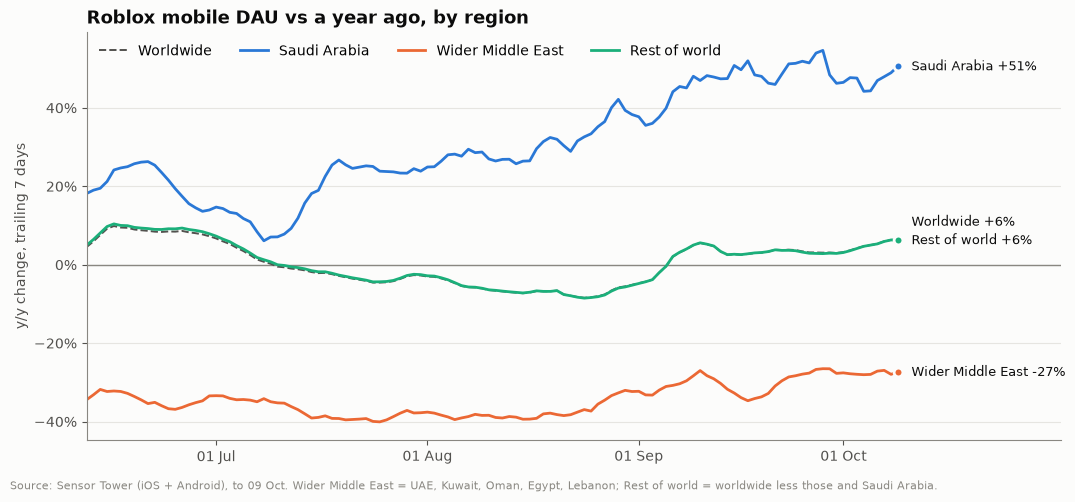

In [18]:
def plot_region_growth(app: str, metric: str, name: str, period: str = "y/y"):
    df = region_data[(app, metric)].apply(growth_7d, lag=LAGS[period])
    decimals = 0 if period == "y/y" else 1
    last = df[["Saudi Arabia", "Wider Middle East", "Worldwide"]].dropna().index.max()
    df = df.loc[last - pd.Timedelta(days=119):last]
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.axhline(0, color=MUTED, lw=1)
    ax.plot(df.index, df["Worldwide"], color=INK2, ls="--", lw=1.4, label="Worldwide")
    labels = []
    for region, color in REGIONS.items():
        ax.plot(df.index, df[region], color=color, label=region)
        ax.scatter([last], [df[region].iloc[-1]], color=color, s=40, zorder=3, edgecolor="#fcfcfb", linewidth=2)
        labels.append([df[region].iloc[-1], f"{region} {df[region].iloc[-1]:+.{decimals}%}"])
    labels.append([df["Worldwide"].iloc[-1], f"Worldwide {df['Worldwide'].iloc[-1]:+.{decimals}%}"])
    labels.sort()
    lo, hi = ax.get_ylim()
    for i in range(1, len(labels)):
        labels[i][0] = max(labels[i][0], labels[i - 1][0] + 0.045 * (hi - lo))
    for y, text in labels:
        ax.text(last + pd.Timedelta(days=2), y, text, fontsize=9, color=INK, va="center")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
    ax.set_xlim(df.index[0], last + pd.Timedelta(days=24))
    ax.set_xticks(pd.date_range(df.index[0], last, freq="MS"))
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
    against = "a year ago" if period == "y/y" else "the previous week"
    ax.set_title(f"{app} mobile {name} vs {against}, by region")
    ax.set_ylabel(f"{period} change, trailing 7 days")
    ax.legend(loc="upper left", ncols=4)
    source_note(fig, f"Source: Sensor Tower (iOS + Android), to {last:%d %b}. Wider Middle East = UAE, Kuwait, Oman, Egypt, Lebanon; "
                     "Rest of world = worldwide less those and Saudi Arabia.")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    return fig


save(plot_region_growth("Roblox", "dau", "DAU", "y/y"), "7_roblox_dau_yoy_by_region")

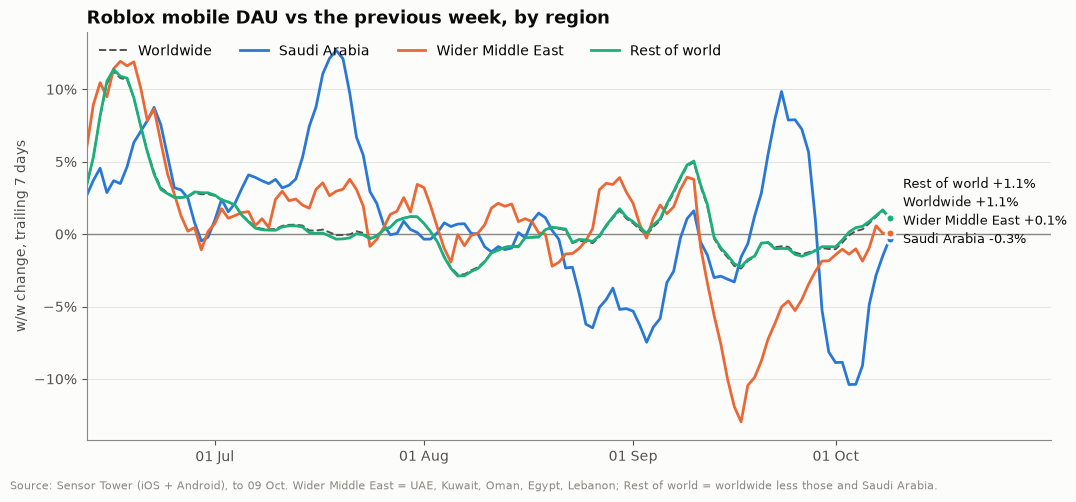

In [19]:
save(plot_region_growth("Roblox", "dau", "DAU", "w/w"), "7b_roblox_dau_wow_by_region")

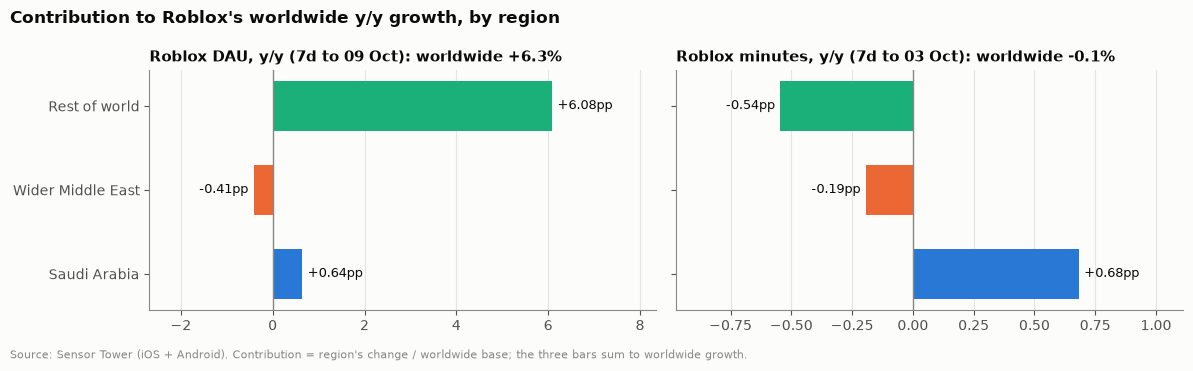

In [20]:
def plot_contributions(tables: dict, col: str, title: str):
    fig, axes = plt.subplots(1, len(tables), figsize=(12, 3.6), sharey=True)
    for ax, (label, t) in zip(axes, tables.items()):
        vals = t.loc[list(REGIONS), col]
        ax.barh(range(len(vals)), vals, color=list(REGIONS.values()), height=0.6)
        for i, v in enumerate(vals):
            ax.annotate(f"{v:+.2f}pp", (v, i), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                        ha="left" if v >= 0 else "right", va="center", fontsize=9, color=INK)
        ax.axvline(0, color=MUTED, lw=1)
        ax.set_yticks(range(len(vals)))
        ax.set_yticklabels(list(REGIONS))
        ax.invert_yaxis()
        ax.grid(axis="y", visible=False)
        ax.grid(axis="x", color=GRID)
        ax.margins(x=0.35)
        total = t.loc["Worldwide", col.replace(" contribution (pp)", "")]
        ax.set_title(f"{label}: worldwide {total:+.1%}", fontsize=11)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
    source_note(fig, "Source: Sensor Tower (iOS + Android). Contribution = region's change / worldwide base; the three bars sum to worldwide growth.")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    return fig


save(plot_contributions({f"Roblox DAU, y/y (7d to {roblox_last:%d %b})": roblox_dau,
                         f"Roblox minutes, y/y (7d to {min_last:%d %b})": roblox_min},
                        "y/y contribution (pp)", "Contribution to Roblox's worldwide y/y growth, by region"),
     "8_roblox_yoy_contribution")

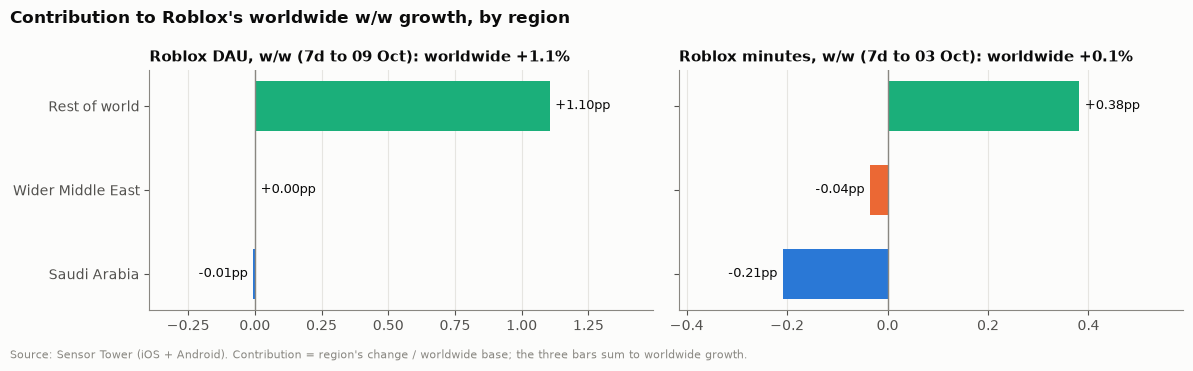

In [21]:
save(plot_contributions({f"Roblox DAU, w/w (7d to {roblox_last:%d %b})": roblox_dau,
                         f"Roblox minutes, w/w (7d to {min_last:%d %b})": roblox_min},
                        "w/w contribution (pp)", "Contribution to Roblox's worldwide w/w growth, by region"),
     "8b_roblox_wow_contribution")

### Contribution week by week

Each bar is one 7-day window, ending on the latest Sensor Tower day and stepping back a week at a time, so the windows don't overlap. The bars show how many percentage points each region added to worldwide growth in that window.
- **Top panel:** Saudi Arabia and the wider Middle East.
- **Bottom panel:** the rest of the world, with the worldwide total marked.

The two panels share the same unit but not the same scale, because the rest of the world is about 97% of DAU.

,Saudi Arabia,Wider Middle East,Rest of world,Worldwide (%),Saudi Arabia (%),Wider Middle East (%)
to Fri 24 Jul,+0.06,-0.01,-0.31,-0.3%,+2.9%,-0.8%
to Fri 31 Jul,+0.00,+0.04,+1.16,+1.2%,+0.1%,+3.4%
to Fri 07 Aug,+0.01,-0.01,-2.78,-2.8%,+0.7%,-0.8%
to Fri 14 Aug,-0.02,+0.02,-0.83,-0.8%,-1.0%,+2.1%
to Fri 21 Aug,-0.01,-0.02,+0.40,+0.4%,-0.4%,-1.9%
to Fri 28 Aug,-0.10,+0.04,+0.57,+0.5%,-4.5%,+3.5%
to Fri 04 Sep,-0.13,+0.01,+0.61,+0.5%,-6.4%,+1.1%
to Fri 11 Sep,-0.01,-0.01,+3.31,+3.3%,-0.6%,-0.9%
to Fri 18 Sep,-0.01,-0.12,-1.71,-1.8%,-0.7%,-10.5%
to Fri 25 Sep,+0.14,-0.06,-1.36,-1.3%,+7.9%,-5.3%


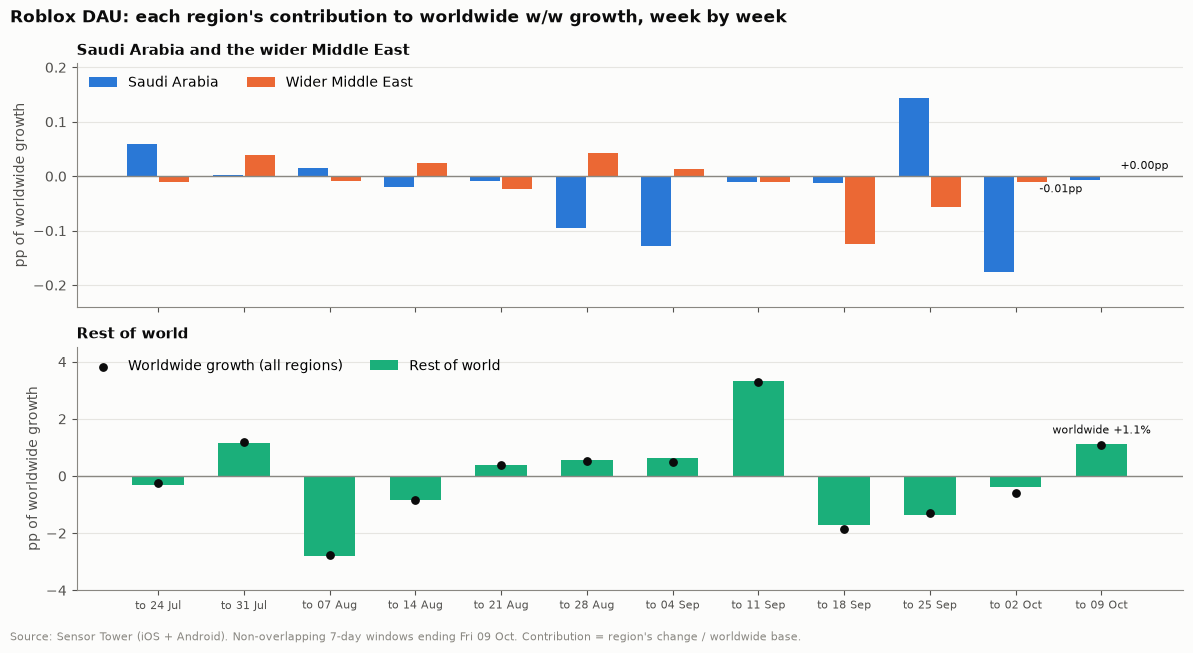

In [22]:
def contribution_history(app: str, metric: str, period: str, weeks: int = 12) -> pd.DataFrame:
    df = region_data[(app, metric)]
    last = df[["Saudi Arabia", "Wider Middle East", "Worldwide"]].dropna().index.max()
    r7 = df.rolling(7, min_periods=7).sum()
    lag = pd.Timedelta(days=LAGS[period])
    rows = {}
    for k in range(weeks - 1, -1, -1):
        end = last - pd.Timedelta(days=7 * k)
        cur, base = r7.loc[end], r7.loc[end - lag]
        rows[end] = {**{r: (cur[r] - base[r]) / base["Worldwide"] * 100 for r in REGIONS},
                     "Worldwide (%)": (cur["Worldwide"] / base["Worldwide"] - 1) * 100,
                     "Saudi Arabia (%)": (cur["Saudi Arabia"] / base["Saudi Arabia"] - 1) * 100,
                     "Wider Middle East (%)": (cur["Wider Middle East"] / base["Wider Middle East"] - 1) * 100}
    return pd.DataFrame(rows).T


def plot_contribution_history(app: str, metric: str, name: str, period: str, weeks: int = 12):
    h = contribution_history(app, metric, period, weeks)
    x = range(len(h))
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
    w = 0.38
    for offset, region, ha, dx in [(-w / 2, "Saudi Arabia", "right", -2), (w / 2, "Wider Middle East", "left", 2)]:
        ax1.bar([i + offset for i in x], h[region], width=w * 0.92, color=REGIONS[region], label=region)
        v = h[region].iloc[-1]
        ax1.annotate(f"{v:+.2f}pp", (len(h) - 1 + offset, v), xytext=(dx, 3 if v >= 0 else -3), textcoords="offset points",
                     ha=ha, va="bottom" if v >= 0 else "top", fontsize=8, color=INK)
    ax1.axhline(0, color=MUTED, lw=1)
    ax1.set_title("Saudi Arabia and the wider Middle East", fontsize=11)
    ax1.set_ylabel("pp of worldwide growth")
    ax1.legend(loc="upper left", ncols=2)
    ax1.margins(y=0.2)
    ax2.bar(x, h["Rest of world"], width=0.6, color=REGIONS["Rest of world"], label="Rest of world")
    ax2.scatter(x, h["Worldwide (%)"], color=INK, s=28, zorder=3, label="Worldwide growth (all regions)")
    v = h["Worldwide (%)"].iloc[-1]
    ax2.annotate(f"worldwide {v:+.1f}%", (len(h) - 1, v), xytext=(0, 8), textcoords="offset points", ha="center",
                 fontsize=8, color=INK)
    ax2.axhline(0, color=MUTED, lw=1)
    ax2.set_title("Rest of world", fontsize=11)
    ax2.set_ylabel("pp of worldwide growth")
    ax2.legend(loc="upper left", ncols=2)
    ax2.margins(y=0.2)
    ax2.set_xticks(list(x))
    ax2.set_xticklabels([f"to {d:%d %b}" for d in h.index], fontsize=8)
    fig.suptitle(f"{app} {name}: each region's contribution to worldwide {period} growth, week by week",
                 x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
    source_note(fig, f"Source: Sensor Tower (iOS + Android). Non-overlapping 7-day windows ending {h.index[-1]:%a %d %b}. "
                     "Contribution = region's change / worldwide base.")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    return fig, h


HIST_FMT = {c: "{:+.2f}" for c in REGIONS} | {c: "{:+.1f}%" for c in ["Worldwide (%)", "Saudi Arabia (%)", "Wider Middle East (%)"]}
fig, roblox_wow_hist = plot_contribution_history("Roblox", "dau", "DAU", "w/w")
save(fig, "8c_roblox_dau_wow_contribution_history")
roblox_wow_hist.set_axis(roblox_wow_hist.index.strftime("to %a %d %b")).style.format(HIST_FMT)

,Saudi Arabia,Wider Middle East,Rest of world,Worldwide (%),Saudi Arabia (%),Wider Middle East (%)
to Fri 24 Jul,+0.40,-0.73,-4.23,-4.6%,+25.0%,-40.0%
to Fri 31 Jul,+0.39,-0.69,-2.44,-2.7%,+23.8%,-37.7%
to Fri 07 Aug,+0.46,-0.71,-5.48,-5.7%,+29.4%,-38.7%
to Fri 14 Aug,+0.40,-0.72,-6.81,-7.1%,+25.7%,-38.9%
to Fri 21 Aug,+0.45,-0.69,-7.36,-7.6%,+30.4%,-38.5%
to Fri 28 Aug,+0.54,-0.58,-6.52,-6.6%,+40.1%,-33.4%
to Fri 04 Sep,+0.50,-0.57,-1.95,-2.0%,+37.7%,-32.0%
to Fri 11 Sep,+0.62,-0.49,+5.08,+5.2%,+48.2%,-28.3%
to Fri 18 Sep,+0.61,-0.58,+2.92,+3.0%,+48.4%,-34.1%
to Fri 25 Sep,+0.70,-0.42,+3.11,+3.4%,+51.9%,-27.9%


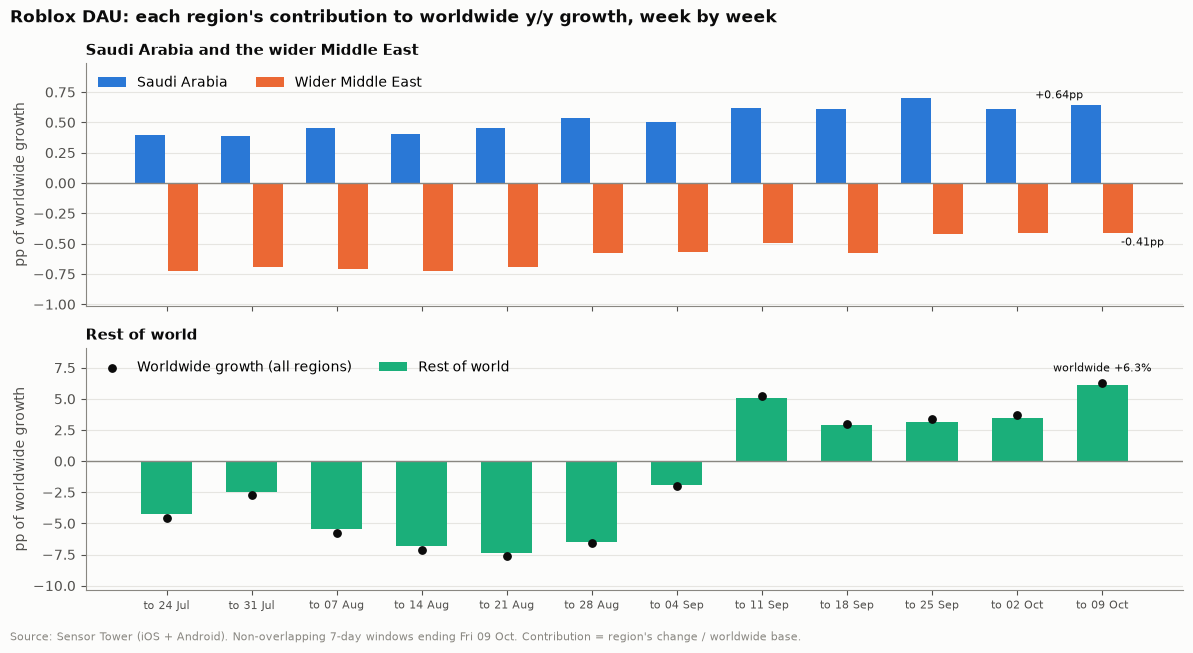

In [23]:
fig, roblox_yoy_hist = plot_contribution_history("Roblox", "dau", "DAU", "y/y")
save(fig, "8d_roblox_dau_yoy_contribution_history")
roblox_yoy_hist.set_axis(roblox_yoy_hist.index.strftime("to %a %d %b")).style.format(HIST_FMT)

In [24]:
# Saudi Arabia day by day: Roblox DAU and its w/w, last four weeks (Sarab's jump was on 8 Oct).
sa = region_data[("Roblox", "dau")][["Saudi Arabia", "Wider Middle East", "Rest of world"]]
sa_last = sa.dropna().index.max()
recent = sa.loc[sa_last - pd.Timedelta(days=27):sa_last]
daily = pd.concat({"DAU": recent, "w/w": sa.pct_change(7, fill_method=None).loc[recent.index]}, axis=1)
daily.index = daily.index.strftime("%a %d %b")
daily.style.format(
    "{:,.0f}", subset=["DAU"]).format("{:+.1%}", subset=["w/w"])

## 6. TikTok engagement by region

**What our TikTok data can show:** the TikTok app's own DAU and minutes by country (Sensor Tower `common.core`, iOS + Android), with the same regions and method as section 5. This is usage of TikTok overall, not engagement with Roblox or صيد الضبّان content.

**What it can't show:** none of our TikTok sources tracks a game's TikTok content by country.

| Source | What it holds | Limits |
|---|---|---|
| Sensor Tower `common.core` | TikTok app DAU and minutes by country, to the latest Sensor Tower day | app-level only |
| Exolyt (`consumer.exolyt_tiktok`) | hashtag views and videos per day | 6 retail hashtags (squishy, needoh, chilis, tripledipper, bathandbodyworks, fivebelow); stopped 16 Jun 2026; no country split |
| Sensor Tower `apps.tiktok_time_spend` | TikTok minutes by in-app surface (feed, search, shop, live) | one country; stopped 18 Jul 2026 |
| Embee (`embee_v2.common.tiktok_*`) | panel TikTok sessions and events | 6 panellists in recent data; timestamps out of range |

To measure TikTok engagement with this game, its hashtags would need tracking, for example #صيد_الضبان, #سراب and #roblox. Exolyt would be the natural place, if the subscription is still active.

In [25]:
tiktok_dau, tt_last = growth_table(region_data[("TikTok", "dau")])
print(f"TikTok DAU, trailing 7 days to {tt_last:%a %d %b}")
tiktok_dau.style.format(FMT)

TikTok DAU, trailing 7 days to Fri 09 Oct


,"avg per day, 7d",share,w/w,w/w contribution (pp),y/y,y/y contribution (pp)
Saudi Arabia,"17,009,071",1.7%,+1.0%,+0.02,+4.6%,+0.08
Wider Middle East,"36,692,545",3.6%,+0.5%,+0.02,+9.0%,+0.34
of which Egypt,"28,709,763",2.9%,+0.7%,+0.02,+11.7%,+0.34
Rest of world,"951,877,513",94.7%,+0.0%,+0.01,+13.3%,+12.53
Worldwide,"1,005,579,129",100.0%,+0.0%,+0.05,+13.0%,+12.96


In [26]:
tiktok_min, tt_min_last = growth_table(region_data[("TikTok", "minutes")])
print(f"TikTok minutes, trailing 7 days to {tt_min_last:%a %d %b}")
tiktok_min.style.format(FMT)

TikTok minutes, trailing 7 days to Sat 03 Oct


,"avg per day, 7d",share,w/w,w/w contribution (pp),y/y,y/y contribution (pp)
Saudi Arabia,"1,597,768,427",1.6%,-3.6%,-0.06,+13.3%,+0.22
Wider Middle East,"3,261,086,308",3.3%,+1.4%,+0.05,+20.4%,+0.66
of which Egypt,"2,583,708,520",2.6%,+1.6%,+0.04,+24.7%,+0.61
Rest of world,"93,181,168,805",95.0%,+1.1%,+1.02,+17.2%,+16.32
Worldwide,"98,040,023,540",100.0%,+1.0%,+1.01,+17.2%,+17.20


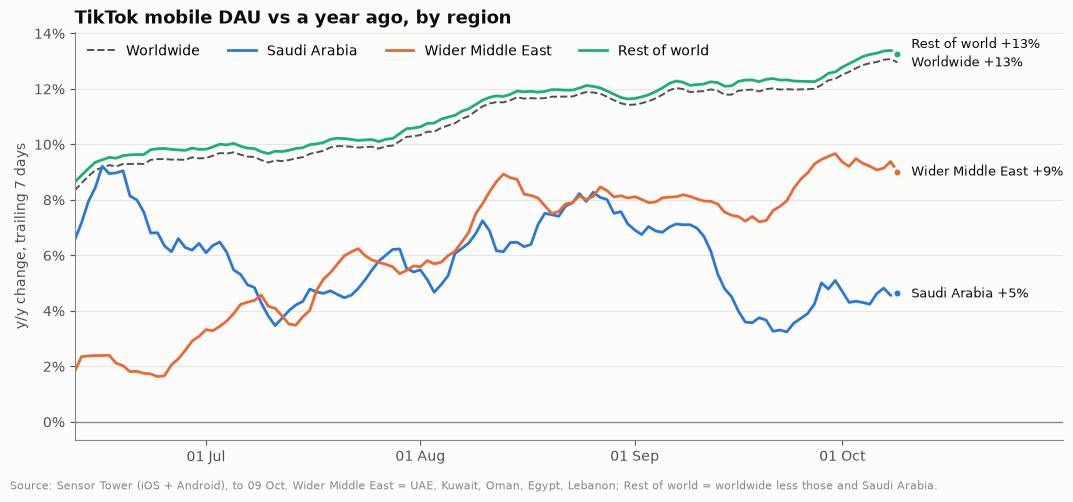

In [27]:
save(plot_region_growth("TikTok", "dau", "DAU", "y/y"), "9_tiktok_dau_yoy_by_region")

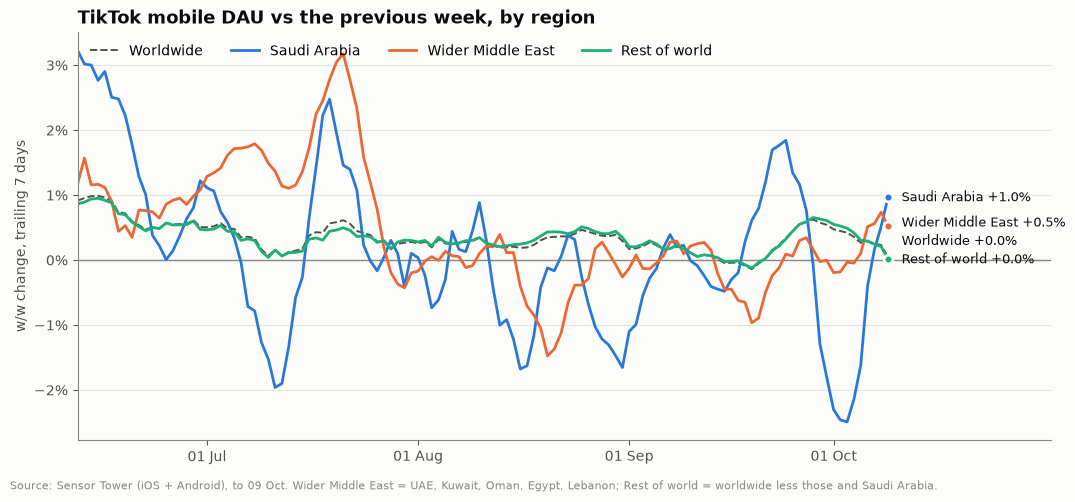

In [28]:
save(plot_region_growth("TikTok", "dau", "DAU", "w/w"), "9b_tiktok_dau_wow_by_region")

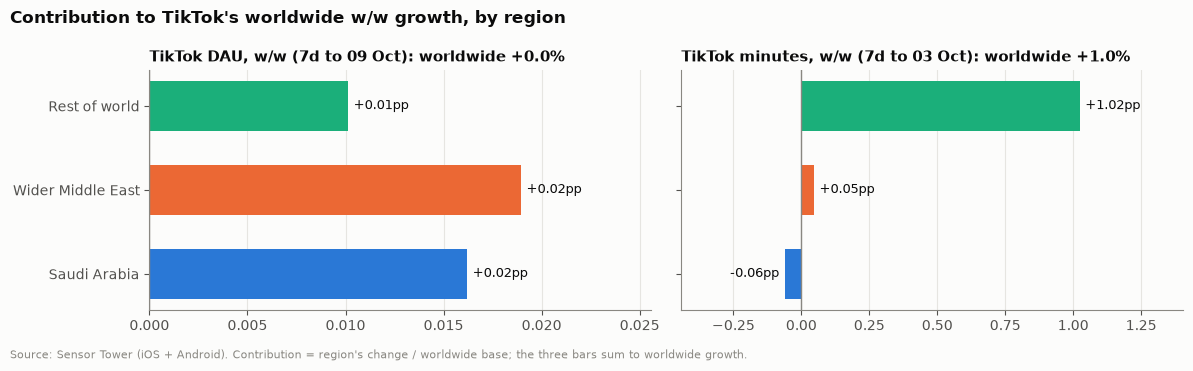

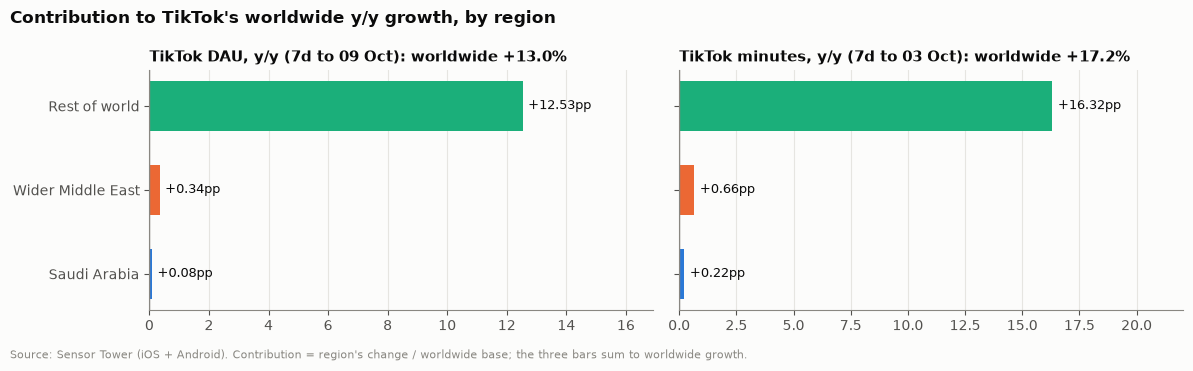

In [29]:
save(plot_contributions({f"TikTok DAU, w/w (7d to {tt_last:%d %b})": tiktok_dau,
                         f"TikTok minutes, w/w (7d to {tt_min_last:%d %b})": tiktok_min},
                        "w/w contribution (pp)", "Contribution to TikTok's worldwide w/w growth, by region"),
     "9c_tiktok_wow_contribution")
save(plot_contributions({f"TikTok DAU, y/y (7d to {tt_last:%d %b})": tiktok_dau,
                         f"TikTok minutes, y/y (7d to {tt_min_last:%d %b})": tiktok_min},
                        "y/y contribution (pp)", "Contribution to TikTok's worldwide y/y growth, by region"),
     "9d_tiktok_yoy_contribution")

,Saudi Arabia,Wider Middle East,Rest of world,Worldwide (%),Saudi Arabia (%),Wider Middle East (%)
to Fri 24 Jul,+0.00,+0.06,+0.35,+0.4%,+0.2%,+1.6%
to Fri 31 Jul,+0.00,-0.01,+0.28,+0.3%,+0.1%,-0.2%
to Fri 07 Aug,+0.00,+0.00,+0.25,+0.3%,+0.2%,+0.1%
to Fri 14 Aug,-0.02,+0.00,+0.21,+0.2%,-0.9%,+0.1%
to Fri 21 Aug,-0.00,-0.05,+0.41,+0.4%,-0.2%,-1.4%
to Fri 28 Aug,-0.02,+0.01,+0.38,+0.4%,-1.2%,+0.3%
to Fri 04 Sep,-0.00,-0.00,+0.28,+0.3%,-0.3%,-0.1%
to Fri 11 Sep,-0.00,+0.01,+0.05,+0.1%,-0.1%,+0.3%
to Fri 18 Sep,+0.00,-0.02,-0.07,-0.1%,+0.3%,-0.7%
to Fri 25 Sep,+0.02,+0.00,+0.42,+0.4%,+1.3%,+0.1%


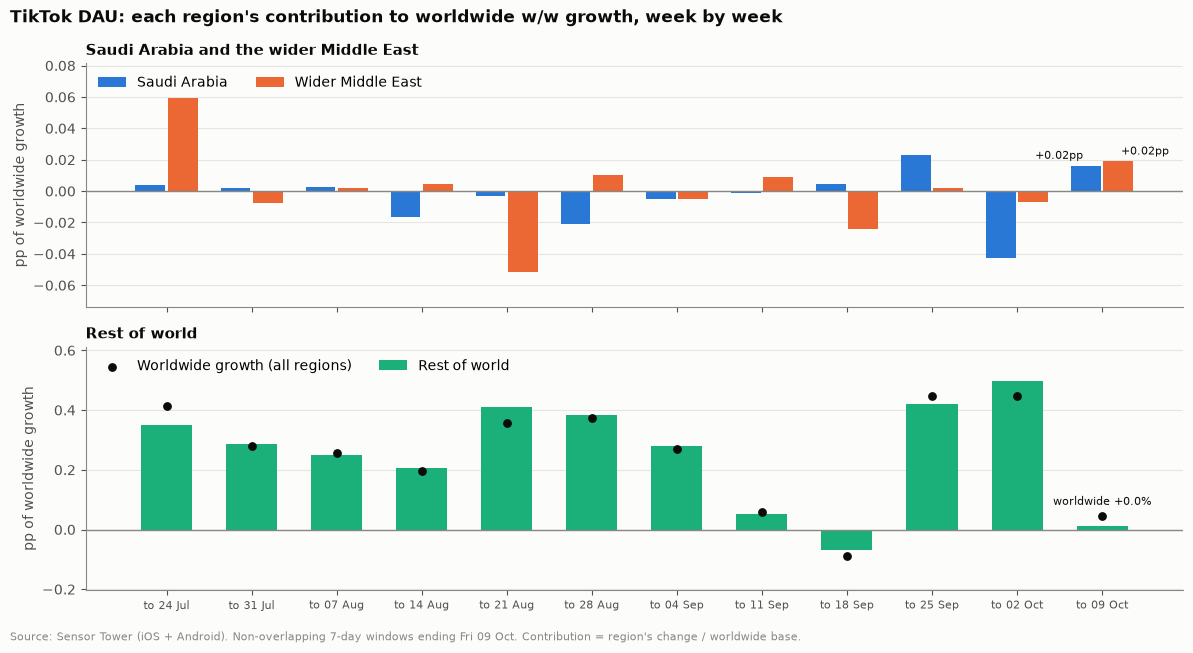

In [30]:
fig, tiktok_wow_hist = plot_contribution_history("TikTok", "dau", "DAU", "w/w")
save(fig, "9e_tiktok_dau_wow_contribution_history")
tiktok_wow_hist.set_axis(tiktok_wow_hist.index.strftime("to %a %d %b")).style.format(HIST_FMT)

In [31]:
# Minutes per DAU per day: how heavily each region uses TikTok against Roblox (trailing 7 days).
rows = {}
for app, (tdau, tmin, last) in {"Roblox": (roblox_dau, roblox_min, min_last), "TikTok": (tiktok_dau, tiktok_min, tt_min_last)}.items():
    d, m = region_data[(app, "dau")], region_data[(app, "minutes")]
    window = slice(last - pd.Timedelta(days=6), last)
    rows[f"{app} min/DAU/day (7d to {last:%d %b})"] = m.loc[window].sum() / d.loc[window].sum()
pd.DataFrame(rows).loc[["Saudi Arabia", "Wider Middle East", "Rest of world", "Worldwide"]].round(0)

,Roblox min/DAU/day (7d to 03 Oct),TikTok min/DAU/day (7d to 03 Oct)
Saudi Arabia,62.0,95.0
Wider Middle East,65.0,89.0
Rest of world,57.0,98.0
Worldwide,57.0,97.0
